[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/main/notebooks/1_create_your_encoder.ipynb)

# Create your own encoder

* **Author**: laquitainesteeve@gmail.com 

* **Goal**: Build an encoder from scratch on synthetic neural data, fit it, save it, load it back and plug it into the package. The true responses are known, so you can check exactly how good the fitted encoder is.

* **Requirements**: TinyImageNet (downloaded on the first run, 240 MB). A GPU helps; on a CPU the settings shrink automatically.

* **Time**: about 1 min on a GPU.

## 1. Setup

### 1.1. Install package

In [1]:
%%time

# on Google Colab install the package from PyPI, without its dependencies: Colab already has
# torch, numpy, scipy and matplotlib, and reinstalling torch is slow and can break the GPU runtime (nothing to do on your own machine)
import sys

if "google.colab" in sys.modules:
    %pip install -q --no-deps --pre multigeom

CPU times: user 4 μs, sys: 0 ns, total: 4 μs
Wall time: 6.2 μs


### 1.2. Imports and parameters

In [2]:
%%time

# move to the repository root (the folder containing environment.yml): data/ and runs/ are read from there
import os
from pathlib import Path

root = Path.cwd().resolve()
while not (root / "environment.yml").exists() and root != root.parent:
    root = root.parent
if (root / "environment.yml").exists():
    os.chdir(root)
print("working folder:", Path.cwd())

# libraries and the package
import copy
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn

import multigeom
from multigeom import compute_fisher, subspace_alignment, validate_encoder
from multigeom.datasets import TinyImageNetDataset, make_synthetic_experiment
from multigeom.encoders import NeuralEncoder, SmallCNNBackbone, load_encoder
from multigeom.encoders.fitting import correlation_per_neuron

# device and random seed
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)         # a fixed seed makes the notebook repeatable

# parameters
N_NEURONS = 50              # neurons to simulate and to predict
NOISE_SIGMA = 0.22          # trial-to-trial noise of the neurons (the paper measures 0.22 in V1)
N_TRAIN, N_TEST = 6000, 2000          # images with neural data, for fitting and for testing
IMAGES_PER_CLASS = 200      # TinyImageNet images per class to train the backbone on (200 classes)
PRETRAIN_EPOCHS = 15
FIT_EPOCHS = 100
SAVE_DIR = Path("runs/getting_started")

if device == "cpu":         # keep the demo to a few minutes on a CPU
    N_TRAIN, N_TEST, IMAGES_PER_CLASS, PRETRAIN_EPOCHS, FIT_EPOCHS = 2000, 1000, 40, 5, 40
print("multigeom", multigeom.__version__, "| device:", device)

working folder: /home/steeve/steeve/idv/code/multigeom-tutorials
multigeom 0.1.0.dev2 | device: cuda
CPU times: user 3.75 s, sys: 189 ms, total: 3.94 s
Wall time: 1.44 s


### 1.3. Custom functions

In [3]:
%%time

def load_images(dataset):
    """All the images of a TinyImageNet dataset as one tensor [N, 1, 64, 64] in [-1, 1]."""
    return torch.stack([dataset[i][0] if isinstance(dataset[i], tuple) else dataset[i] for i in range(len(dataset))])

# correlation of the encoder's predictions on the test images with the true and with the recorded responses
def score(encoder):
    pred = encoder.predict(x_test, device=device)
    return correlation_per_neuron(pred, c_test).mean(), correlation_per_neuron(pred, r_test).mean()

## 2. Make synthetic neural data

`make_synthetic_experiment` shows TinyImageNet images (`x`) to V1-like Gabor neurons. Their true responses (`c`) are a **ground truth**; the recorded ones (`r`) have noise added.

<details><summary>Details</summary>

The neurons are a `GaborTeacher`: each has a Gabor filter and responds with its energy. They follow the encoder contract, so their Fisher information is also a ground truth. The recorded responses are `clean + sigma * N(0, 1)`, and the **noise ceiling** is the best correlation any model can reach on them. `train` is for fitting, `test` for scoring; `c` is never used when fitting.

</details>

In [4]:
%%time

# simulate the experiment: images, true and recorded responses, split for fitting and testing
(teacher, x_train, x_test, r_train, r_test, c_train, c_test, ceiling) = make_synthetic_experiment(
    N_NEURONS, NOISE_SIGMA, N_TRAIN, N_TEST)      # downloads TinyImageNet the first time (240 MB)
print(f"{len(x_train) + len(x_test)} images with {N_NEURONS} neurons each")
print(f"noise ceiling (mean correlation of the noisy with the clean responses): {ceiling.mean():.3f}")

8000 images with 50 neurons each, loaded in 2 s
noise ceiling (mean correlation of the noisy with the clean responses): 0.976
CPU times: user 2.68 s, sys: 156 ms, total: 2.84 s
Wall time: 2.37 s


Plot the receptive fields of some neurons (top), and their recorded against their true responses (bottom).

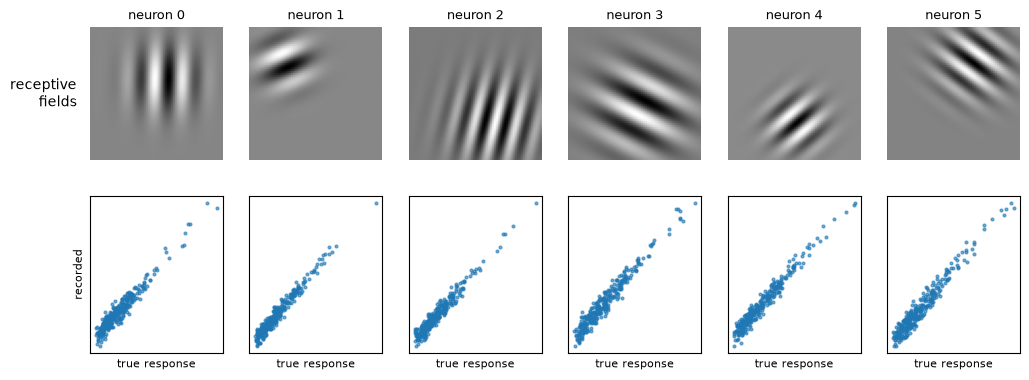

In [5]:
%%time

# top: receptive fields of the first neurons; bottom: recorded against true responses
fig, axes = plt.subplots(2, 6, figsize=(12, 4.3), gridspec_kw={"height_ratios": [1, 1.1]})
for n, ax in enumerate(axes[0]):
    ax.imshow(teacher.filters[n, 0].numpy(), cmap="gray"); ax.set_title(f"neuron {n}", fontsize=9); ax.axis("off")
axes[0, 0].text(-0.1, 0.5, "receptive\nfields", transform=axes[0, 0].transAxes, ha="right", va="center")
for n, ax in enumerate(axes[1]):
    ax.scatter(c_train[:300, n], r_train[:300, n], s=4, alpha=0.6)
    ax.set_xlabel("true response", fontsize=8); ax.set_xticks([]); ax.set_yticks([])
axes[1, 0].set_ylabel("recorded", fontsize=8)
plt.show()

## 3. Define the encoder backbone and train it

The **backbone** turns an image into a feature map. `SmallCNNBackbone` is first trained on an unrelated task: classifying the 200 TinyImageNet classes.

<details><summary>Details</summary>

This is an ordinary PyTorch loop: replace the backbone, the task and the loop by your own. A backbone maps images `[B, 1, 64, 64]` to a feature map `[B, C, S, S]` and has the attributes `out_channels` (C) and `out_spatial` (S). The paper's encoders use a pretrained ImageNet network instead: see notebook 0.

</details>

40000 images, 200 classes
backbone trained in 14 s: classification accuracy 0.21 on the training images (chance is 0.005)


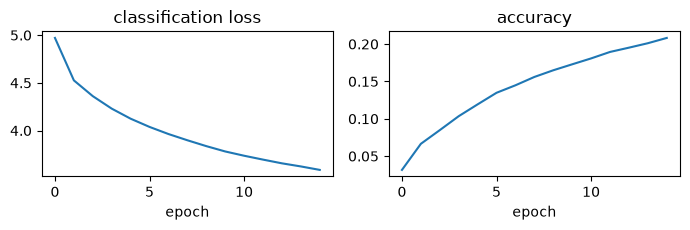

In [6]:
%%time

# 1. the classification task: TinyImageNet images and their 200 class labels
train_set = TinyImageNetDataset("train", images_per_class=IMAGES_PER_CLASS, return_labels=True)
pretrain_images = load_images(train_set).to(device)
pretrain_labels = torch.tensor(train_set.labels, device=device)
print(f"{len(train_set)} images, {len(set(train_set.labels))} classes")

# 2. the backbone, with a throw-away classification head
backbone = SmallCNNBackbone(channels=(32, 64, 64)).to(device)
head = nn.Linear(backbone.out_channels, 200).to(device)             # classification head, used for training only
optimizer = torch.optim.AdamW(list(backbone.parameters()) + list(head.parameters()), lr=2e-3, weight_decay=1e-4)

# 3. training loop: classify the images from the averaged feature map
history = {"loss": [], "accuracy": []}
t0 = time.time()
for epoch in range(PRETRAIN_EPOCHS):
    backbone.train()
    order = torch.randperm(len(pretrain_images), device=device)
    total, correct = 0.0, 0
    for i in range(0, len(order), 128):
        idx = order[i: i + 128]
        logits = head(backbone(pretrain_images[idx]).mean(dim=(-2, -1)))      # average the feature map, then classify
        loss = nn.functional.cross_entropy(logits, pretrain_labels[idx])
        optimizer.zero_grad(); loss.backward(); optimizer.step()
        total += loss.item() * len(idx); correct += (logits.argmax(1) == pretrain_labels[idx]).sum().item()
    history["loss"].append(total / len(order)); history["accuracy"].append(correct / len(order))
print(f"backbone trained in {time.time() - t0:.0f} s: classification accuracy {history['accuracy'][-1]:.2f} on the training images "
      f"(chance is 0.005)")
backbone = backbone.cpu()
del pretrain_images

# 4. training curves
fig, ax = plt.subplots(1, 2, figsize=(7, 2.4))
ax[0].plot(history["loss"]); ax[0].set_xlabel("epoch"); ax[0].set_title("classification loss")
ax[1].plot(history["accuracy"]); ax[1].set_xlabel("epoch"); ax[1].set_title("accuracy")
plt.tight_layout(); plt.show()

## 4. Build the encoder and fit its readout

The **readout** is the part fitted to neural data, chosen by name in `NeuralEncoder(backbone, n_neurons, readout=...)`. `fit_readout` fits it on the frozen backbone's features; we score each readout against the true responses.

<details><summary>Details</summary>

| `readout=` | each neuron reads the feature map with... | parameters |
|---|---|---|
| `"linear"` | the average of the map over space, then a linear map | N (C + 1) |
| `"gaussian"` | a Gaussian window with a learned centre and width (the paper's readout) | N (C + 4) |
| `"factorized"` | a free spatial window and feature weights | N (S² + C + 1) |

`fit_readout` uses AdamW and the mean squared error, keeps 5% of the images for validation and keeps the best epoch. The last row of the table uses a backbone that was never trained.

</details>

In [7]:
%%time

# 1. fit each readout on a copy of the trained backbone, and score it on the test images
fits = {}
for name in ("linear", "gaussian", "factorized"):
    enc = NeuralEncoder(copy.deepcopy(backbone), N_NEURONS, readout=name)
    t0 = time.time()
    report = enc.fit_readout(x_train, r_train, epochs=FIT_EPOCHS, lr=3e-3, batch_size=128, device=device, verbose=False)
    fits[name] = (enc, report, score(enc), time.time() - t0)
# 2. for comparison: a Gaussian readout on a backbone that was never trained
untrained = NeuralEncoder(SmallCNNBackbone(channels=(32, 64, 64)), N_NEURONS, readout="gaussian")
untrained.fit_readout(x_train, r_train, epochs=FIT_EPOCHS, lr=3e-3, batch_size=128, device=device, verbose=False)
fits["gaussian, untrained backbone"] = (untrained, None, score(untrained), None)

# 3. results table
print(f"{'readout':30s} {'validation':>10s} {'test vs truth':>14s} {'test vs recorded':>17s}")
for name, (enc, report, (vs_clean, vs_noisy), seconds) in fits.items():
    val = f"{report.best_val_corr:.3f}" if report else "-"
    print(f"{name:30s} {val:>10s} {vs_clean:14.3f} {vs_noisy:17.3f}")
print(f"{'noise ceiling':30s} {'':>10s} {'1.000':>14s} {ceiling.mean():17.3f}")

readout                        validation  test vs truth  test vs recorded
linear                              0.478          0.497             0.485
gaussian                            0.629          0.652             0.637
factorized                          0.626          0.650             0.635
gaussian, untrained backbone            -          0.450             0.441
noise ceiling                                      1.000             0.976


*Test vs truth* is the correlation with the noise-free responses (only synthetic data give it); *test vs recorded* is what an experiment would report. We keep the readout with the best **validation** correlation, never using the test images.

<details><summary>Details</summary>

The Gaussian window beats the linear readout because these neurons look at one place in the image, and a trained backbone beats an untrained one. The score is below the ceiling because a small CNN lacks the neurons' exact Gabor features; a wider backbone, other training data or a longer fit close part of the gap.

</details>

selected readout: gaussian
NeuralEncoder: backbone SmallCNNBackbone (out [C=64, 16, 16]), readout GaussianReadout, 50 neurons, 3,400 trainable / 59,976 parameters
fitted on 5700 images, validated on 300: best epoch 76, validation correlation 0.629


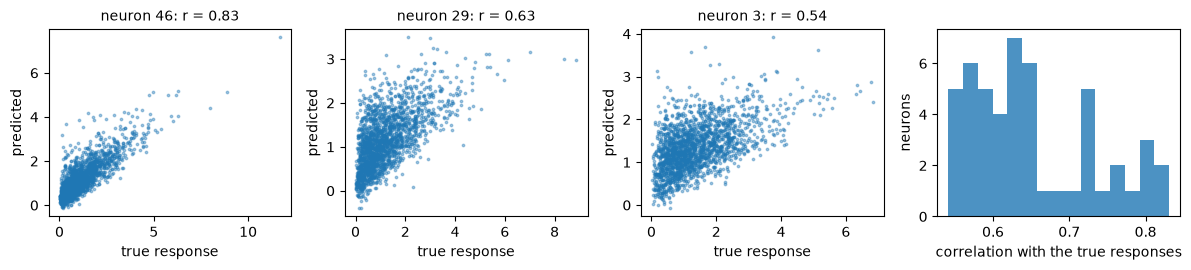

In [8]:
%%time

# 1. keep the readout with the best validation correlation
best = max((n for n in fits if fits[n][1] is not None), key=lambda n: fits[n][1].best_val_corr)
encoder = fits[best][0]
print("selected readout:", best)
print(encoder.summary())
print(fits[best][1])

# 2. its predictions against the true responses on the test images
pred = encoder.predict(x_test, device=device)
corr = correlation_per_neuron(pred, c_test)
fig, axes = plt.subplots(1, 4, figsize=(12, 2.8))
for ax, n in zip(axes[:3], np.argsort(corr)[[-1, len(corr) // 2, 0]]):
    ax.scatter(c_test[:, n], pred[:, n], s=3, alpha=0.4); ax.set_title(f"neuron {n}: r = {corr[n]:.2f}", fontsize=10)
    ax.set_xlabel("true response"); ax.set_ylabel("predicted")
axes[3].hist(corr, bins=15, alpha=0.8, label="fitted encoder")
axes[3].set_xlabel("correlation with the true responses"); axes[3].set_ylabel("neurons")
plt.tight_layout(); plt.show()

## 5. Write your own backbone and readout

Write them as `nn.Module` classes and name them with `@register_backbone("name")` and `@register_readout("name")`. The name is saved with the encoder, so that `NeuralEncoder.load` can rebuild it. Below: `gabor_bank` (fixed Gabor-energy features) and `softplus` (a positive linear readout).

<details><summary>Details</summary>

| Part | Maps | Required |
|---|---|---|
| backbone | images `[B, 1, 64, 64]` to a feature map `[B, C, S, S]` | attributes `out_channels` (C) and `out_spatial` (S) |
| readout | the feature map `[B, C, S, S]` to responses `[B, N]` | constructor `(n_neurons, n_channels, spatial, dropout)` |

Give every constructor argument a default or pass it explicitly: the saved architecture records the arguments. `gabor_bank` computes the energy of 16 oriented Gabor filters (8 orientations, 2 phases), a standard model of V1 complex cells, and has no parameters to train. `softplus` averages each channel over space, applies one linear map and a softplus: the `"linear"` readout plus an output nonlinearity.

</details>

In [ ]:
%%time

import math

import torch.nn.functional as F
from multigeom.encoders import register_backbone, register_readout


@register_backbone("gabor_bank")
class GaborBankBackbone(nn.Module):
    """Energy of oriented Gabor filters. Nothing to train."""

    out_spatial = 16                   # 64 x 64 pixels, pooled by 4

    def __init__(self, n_orientations: int = 8, size: int = 11,
                 wavelength: float = 6.0):
        super().__init__()
        self.out_channels = 2 * n_orientations      # 2 phases each
        # Gabor filters: 8 orientations x 2 phases (even and odd), with a Gaussian envelope
        r = torch.arange(size) - size // 2
        yy, xx = torch.meshgrid(r, r, indexing="ij")
        env = torch.exp(-(xx**2 + yy**2) / (2 * (size / 4) ** 2))
        filters = []
        for k in range(n_orientations):
            a = math.pi * k / n_orientations
            u = xx * math.cos(a) + yy * math.sin(a)
            for phase in (0.0, math.pi / 2):        # even, odd filter
                g = env * torch.cos(2 * math.pi * u / wavelength + phase)
                filters.append(g - g.mean())
        w = torch.stack(filters)[:, None]
        norm = w.flatten(1).norm(dim=1)[:, None, None, None]
        self.register_buffer("filters", w / norm)   # fixed, not trained

    def forward(self, x):                           # -> [B, 16, 16, 16]
        out = F.conv2d(x, self.filters, padding="same") ** 2
        return F.avg_pool2d(out, 4)


@register_readout("softplus")
class SoftplusReadout(nn.Module):
    """Spatial mean, one linear map, positive responses."""

    def __init__(self, n_neurons: int, n_channels: int, spatial: int,
                 dropout: float = 0.0):
        super().__init__()
        self.linear = nn.Linear(n_channels, n_neurons)
        self.dropout = nn.Dropout(dropout)

    def forward(self, features):                    # [B, C, S, S] -> [B, N]
        x = self.dropout(features).mean(dim=(2, 3))
        return F.softplus(self.linear(x))


Fit our readout and two built-in ones on the same backbone, then check that the custom encoder passes the contract, saves and reloads.

In [9]:
%%time

# Our readout against two built-in ones, on the same backbone.
custom = {}
for readout in ("softplus", "linear", "gaussian"):
    enc = NeuralEncoder(GaborBankBackbone(), N_NEURONS, readout=readout)
    report = enc.fit_readout(x_train, r_train, epochs=FIT_EPOCHS, lr=3e-3,
                             batch_size=128, device=device, verbose=False)
    custom[readout] = (enc, report, score(enc))

print(f"{'gabor_bank backbone +':24s} {'validation':>10s} "
      f"{'test vs truth':>14s} {'test vs recorded':>17s}")
for readout, (enc, report, (vs_clean, vs_noisy)) in custom.items():
    print(f"{readout + ' readout':24s} {report.best_val_corr:10.3f} "
          f"{vs_clean:14.3f} {vs_noisy:17.3f}")
print(f"{'noise ceiling':24s} {'':>10s} {'1.000':>14s} {ceiling.mean():17.3f}")

# It is a complete encoder: it satisfies the contract, saves and reloads.
custom_encoder = custom["softplus"][0]
print(custom_encoder.summary())
report = validate_encoder(custom_encoder, sigma=NOISE_SIGMA)
print("contract:", report.warnings or "satisfied")
SAVE_DIR.mkdir(parents=True, exist_ok=True)
custom_path = custom_encoder.save(SAVE_DIR / "custom_encoder.pt",
                                  area="synthetic")
reloaded_custom = NeuralEncoder.load(custom_path, device=device)
assert torch.allclose(reloaded_custom.predict(x_test[:20]),
                      custom_encoder.predict(x_test[:20]), atol=1e-5)
config = custom_encoder.config
print("saved and reloaded from the registered names:",
      config["backbone"]["name"], "+", config["readout"]["name"])

gabor_bank backbone +    validation  test vs truth  test vs recorded
softplus readout              0.422          0.432             0.422
linear readout                0.432          0.445             0.435
gaussian readout              0.616          0.629             0.614
noise ceiling                                1.000             0.976
NeuralEncoder: backbone GaborBankBackbone (out [C=16, 16, 16]), readout SoftplusReadout, 50 neurons, 850 trainable / 850 parameters
contract: ["R9: responses have std 0.0958 over random test images, while the noise sigma is 0.22; the pipeline expects responses of order 1 (for example z-scored). Rescale the model's output or set sigma accordingly. (Random noise images only approximate natural-image statistics.)"]
saved and reloaded from the registered names: gabor_bank + softplus


Your classes work like the built-in ones: `fit_readout`, `predict`, `summary`, `save` and `validate_encoder`. The encoder selected in section 4 is the one used in the rest of the notebook.

<details><summary>Details</summary>

The `softplus` and `linear` readouts average over space, so they cannot tell where a neuron looks; the Gaussian window can, which is why it usually scores higher here. A saved encoder that uses your classes can only be loaded where they are registered: run the cell that defines them first (section 9 shows how to put them in the package).

</details>

## 6. Save and load the encoder

`encoder.save(path)` writes the weights and the architecture; `NeuralEncoder.load(path)` (or `load_encoder(path)`) rebuilds the encoder from that file alone.

<details><summary>Details</summary>

This works because the backbone and the readout are registered by name (section 5). `encoder.load_checkpoint(path)` loads only the weights into an encoder that you built yourself.

</details>

In [10]:
%%time

# 1. save: weights, architecture and metadata in one file (the teacher too, for notebook 2)
SAVE_DIR.mkdir(parents=True, exist_ok=True)
path = encoder.save(SAVE_DIR / "encoder.pt", area="synthetic", noise_sigma=NOISE_SIGMA, test_corr_vs_truth=float(corr.mean()))
torch.save({"state_dict": teacher.state_dict(), "n_neurons": N_NEURONS, "seed": 0}, SAVE_DIR / "teacher.pt")   # the ground truth, for notebook 3
print("saved:", path, f"({path.stat().st_size / 1e6:.1f} MB)")
print("architecture:", encoder.config)

# 2. reload from the file alone, and check that the predictions are identical
reloaded = NeuralEncoder.load(path, device=device)
same = torch.allclose(reloaded.predict(x_test[:50]), encoder.predict(x_test[:50]), atol=1e-5)
print("the reloaded encoder gives the same predictions:", same)
print("metadata:", {k: v for k, v in torch.load(path, weights_only=False)["metadata"].items()})
assert same and torch.allclose(load_encoder(path, device=device).predict(x_test[:5]), encoder.predict(x_test[:5]), atol=1e-5)

saved: runs/getting_started/encoder.pt (0.2 MB)
architecture: {'backbone': {'name': 'small_cnn', 'kwargs': {'channels': (32, 64, 64)}}, 'n_neurons': 50, 'readout': {'name': 'gaussian', 'kwargs': {'n_neurons': 50, 'n_channels': 64, 'spatial': 16, 'dropout': 0.25}}}
the reloaded encoder gives the same predictions: True
metadata: {'area': 'synthetic', 'noise_sigma': 0.22, 'test_corr_vs_truth': 0.6523221186041671}


## 7. Use it in the package

We compute the Fisher information J(x) of the fitted encoder and of the ground-truth teacher at the same image.

contract satisfied: 50 neurons | warnings: none


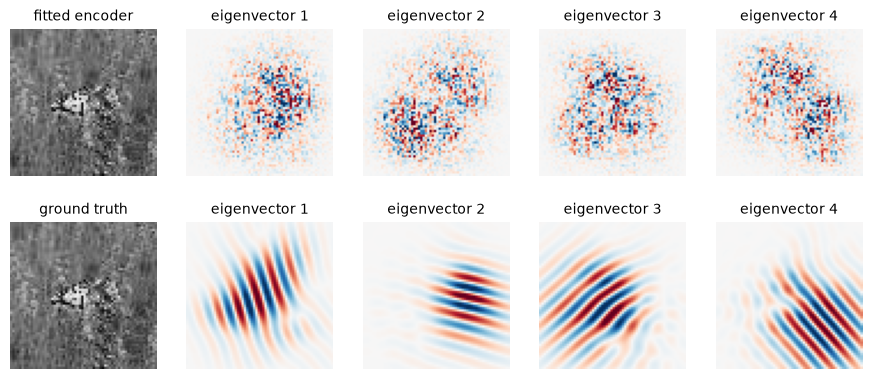

subspace alignment between the fitted encoder and the ground truth (1 = same subspace, chance = k / 4096):
  top  1 eigenvectors: 0.004   (chance 0.0002)
  top  5 eigenvectors: 0.014   (chance 0.0012)
  top 10 eigenvectors: 0.019   (chance 0.0024)


In [11]:
%%time

# 1. check the encoder contract
report = validate_encoder(encoder, sigma=NOISE_SIGMA)
print("contract satisfied:", report.n_neurons, "neurons | warnings:", report.warnings or "none")

# 2. J(x) of the fitted encoder and of the ground truth at one test image
dev = torch.device(device)
x = x_test[:1]
j_fit = compute_fisher(image=x, encoder=encoder.to(dev), sigma=NOISE_SIGMA, top_k=20, device=dev)
j_true = compute_fisher(image=x, encoder=teacher.to(dev), sigma=NOISE_SIGMA, top_k=20, device=dev)

# 3. their leading eigenvectors
fig, axes = plt.subplots(2, 5, figsize=(11, 4.6))
for row, (label, j) in enumerate([("fitted encoder", j_fit), ("ground truth", j_true)]):
    axes[row, 0].imshow(x[0, 0], cmap="gray", vmin=-1, vmax=1); axes[row, 0].set_title(f"{label}", fontsize=10)
    for k in range(4):
        v = j.eigenvectors[k].reshape(64, 64).cpu(); m = v.abs().quantile(0.99)
        axes[row, k + 1].imshow(v, cmap="RdBu_r", vmin=-m, vmax=m); axes[row, k + 1].set_title(f"eigenvector {k + 1}", fontsize=10)
for ax in axes.ravel(): ax.axis("off")
plt.show()

# how well do the leading eigenvectors of the fitted encoder match the ground truth, over 20 images?
scores = {k: [] for k in (1, 5, 10)}
for i in range(20):
    xi = x_test[i: i + 1]
    a = compute_fisher(image=xi, encoder=encoder, sigma=NOISE_SIGMA, top_k=10, device=dev)
    b = compute_fisher(image=xi, encoder=teacher, sigma=NOISE_SIGMA, top_k=10, device=dev)
    for k in scores:
        scores[k].append(subspace_alignment(a.eigenvectors.cpu(), b.eigenvectors.cpu(), k))
print("subspace alignment between the fitted encoder and the ground truth (1 = same subspace, chance = k / 4096):")
for k, v in scores.items():
    print(f"  top {k:2d} eigenvectors: {np.mean(v):.3f}   (chance {k / 4096:.4f})")

A good fit of the responses does not guarantee that the geometry is recovered: the paper studies this (notebook 3).

## 8. Plug in any other PyTorch model

Any deterministic, differentiable `nn.Module` that maps images `[B, 1, 64, 64]` in `[-1, 1]` to responses `[B, N]` works. `validate_encoder` names the rule a model breaks.

In [ ]:
%%time

class MyModel(nn.Module):
    """Any model of your own that is already fitted: here a tiny random convolutional network."""

    def __init__(self, n_neurons=20):
        super().__init__()
        torch.manual_seed(0)
        self.n_neurons = n_neurons
        self.conv = nn.Conv2d(1, 4, 8, stride=8)
        self.linear = nn.Linear(4 * 8 * 8, n_neurons)

    def forward(self, x):
        return torch.tanh(self.linear(torch.relu(self.conv(x)).flatten(1)))


class Broken(MyModel):                                      # a rule violation
    def forward(self, x):
        return super().forward(x).detach()                  # cuts the gradient: J(x) needs it


Validate a tiny random model, compute its Fisher information, and show the error raised for a model that breaks the contract.

In [12]:
%%time

# 1. a model of your own passes the contract check and gives a J(x)
my_model = MyModel()
print(validate_encoder(my_model, sigma=NOISE_SIGMA))
fisher = compute_fisher(image=x.cpu(), encoder=my_model, sigma=NOISE_SIGMA, top_k=5, device=torch.device("cpu"))
print("leading eigenvalues of J(x):", [f"{v:.3g}" for v in fisher.eigenvalues.tolist()])

# 2. a model that breaks the contract is rejected, with a message that names the rule
try:
    validate_encoder(Broken())
except multigeom.EncoderContractError as err:
    print("rejected:", err)

EncoderReport(n_neurons=20, response_std=0.10258577764034271, warnings=[])
leading eigenvalues of J(x): ['2.15', '1.85', '1.66', '1.52', '1.44']
rejected: encoder contract, rule R5: the output does not depend differentiably on the input (torch.no_grad(), detach() or a non-differentiable operation in forward)


## 9. Contribute your encoder to the package

Add the class to `multigeom/encoders/backbones.py` or `readout.py` with its decorator, export it in `multigeom/encoders/__init__.py`, add a CPU unit test and open a pull request against `develop`. Guide: [Contributing → Add an encoder](https://multigeom.github.io/multigeom/contributing.html#add-an-encoder).

<details><summary>Details</summary>

Add the class name to the existing import line of its module and to `__all__` in `multigeom/encoders/__init__.py`, so that users can write `from multigeom.encoders import GaborBankBackbone`. A class in a new module is registered, and so found when a saved encoder is loaded, only if that file imports the module.

</details>

## 10. Recap

| To do | Call |
|---|---|
| make synthetic neurons with a ground truth | `GaborTeacher`, `make_synthetic_neural_data`, `noise_ceiling` |
| define a backbone | any `nn.Module` with `out_channels` and `out_spatial`, e.g. `SmallCNNBackbone` |
| build the encoder | `NeuralEncoder(backbone, n_neurons, readout="gaussian")` |
| fit it to neural data | `encoder.fit_readout(images, responses)` |
| predict neural responses | `encoder.predict(images)` |
| save and load | `encoder.save(path)`, `NeuralEncoder.load(path)`, `load_encoder(path)` |
| register your own backbone or readout | `@register_backbone("name")`, `@register_readout("name")` (section 5) |
| check the contract | `multigeom.validate_encoder(model)` |
| contribute an encoder to the package | section 9 |

**Next**: [notebook 2](2_compute_g.ipynb) trains the diffusion model for this encoder and runs the pipeline: Fisher information J(x), multi-scale metric G(x), and the figures.